# Daily Demand Forecasting – End-to-End ML Mini Project
**Goal:** predict `total_orders` (daily order demand) from the other columns.
**Problem type:** *Regression* (the target is a continuous number, not a class).

Flow: Data Understanding → Cleaning → EDA → Correlation → Feature Engineering → Encoding → Split & Scale → Feature Selection → Models → Evaluation → Tuning → Final Model → Save → API → UI → Docker/Render

## 0. Imports

In [1]:
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# 1. Data Understanding

### 1.1 Load the dataset

In [2]:
df = pd.read_csv("Daily Demand Forecasting Orders.csv")
df.head()

,Unnamed: 0,"Week of the month (first week, second, third, fourth or fifth week",Day of the week (Monday to Friday),Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders)
0,0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65556,44914,188411,14793,539.577
1,1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40419,21399,89461,7679,224.675
2,2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11992,3452,21305,14947,129.412
3,3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49971,33703,69054,18423,317.120
4,4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48534,19646,16411,20257,210.517


### 1.2 Rename the columns (the original names are long and hard to type)

In [3]:
df.columns = [
    "row_id", "week_of_month", "day_of_week",
    "non_urgent_orders", "urgent_orders",
    "order_type_a", "order_type_b", "order_type_c",
    "fiscal_sector_orders", "traffic_controller_orders",
    "banking_orders_1", "banking_orders_2", "banking_orders_3",
    "total_orders",
]
df.head()

,row_id,week_of_month,day_of_week,non_urgent_orders,urgent_orders,order_type_a,order_type_b,order_type_c,fiscal_sector_orders,traffic_controller_orders,banking_orders_1,banking_orders_2,banking_orders_3,total_orders
0,0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65556,44914,188411,14793,539.577
1,1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40419,21399,89461,7679,224.675
2,2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11992,3452,21305,14947,129.412
3,3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49971,33703,69054,18423,317.120
4,4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48534,19646,16411,20257,210.517


### 1.3 Number of rows and columns

In [4]:
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 60
Columns : 14


### 1.4 Data types and info

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   row_id                     60 non-null     int64  
 1   week_of_month              60 non-null     int64  
 2   day_of_week                60 non-null     int64  
 3   non_urgent_orders          60 non-null     float64
 4   urgent_orders              60 non-null     float64
 5   order_type_a               60 non-null     float64
 6   order_type_b               60 non-null     float64
 7   order_type_c               60 non-null     float64
 8   fiscal_sector_orders       60 non-null     float64
 9   traffic_controller_orders  60 non-null     int64  
 10  banking_orders_1           60 non-null     int64  
 11  banking_orders_2           60 non-null     int64  
 12  banking_orders_3           60 non-null     int64  
 13  total_orders               60 non-null     float64
d

### 1.5 Identify numerical and categorical columns

In [6]:
# week_of_month (1-5) and day_of_week (2-6) are stored as numbers but they are really CATEGORIES.
categorical_cols = ["week_of_month", "day_of_week"]
target_col = "total_orders"
numerical_cols = [c for c in df.columns if c not in categorical_cols + [target_col, "row_id"]]

print("Categorical columns:", categorical_cols)
print("Numerical columns  :", numerical_cols)
print("Target variable    :", target_col)
print("Ignored (just an index):", "row_id")

Categorical columns: ['week_of_month', 'day_of_week']
Numerical columns  : ['non_urgent_orders', 'urgent_orders', 'order_type_a', 'order_type_b', 'order_type_c', 'fiscal_sector_orders', 'traffic_controller_orders', 'banking_orders_1', 'banking_orders_2', 'banking_orders_3']
Target variable    : total_orders
Ignored (just an index): row_id


**Meaning of the fields**
- `week_of_month` 1–5, `day_of_week` 2–6 (2 = Monday … 6 = Friday)
- `non_urgent_orders`, `urgent_orders` – orders by urgency
- `order_type_a/b/c` – orders by type
- `fiscal_sector_orders`, `traffic_controller_orders` – orders from those sectors
- `banking_orders_1/2/3` – orders from three banks
- `total_orders` – **target**

*(The assignment mentions "churn / non-churn" because it is a generic template. Our target is a number, so there is no class label – we do regression instead of classification.)*

### 1.6 Descriptive statistics

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
row_id,60.0,29.500000,17.464249,0.000,14.75000,29.5000,44.25000,59.000
week_of_month,60.0,3.016667,1.282102,1.000,2.00000,3.0000,4.00000,5.000
day_of_week,60.0,4.033333,1.401775,2.000,3.00000,4.0000,5.00000,6.000
non_urgent_orders,60.0,172.554933,69.505788,43.651,125.34800,151.0625,194.60650,435.304
urgent_orders,60.0,118.920850,27.170929,77.371,100.88800,113.1145,132.10825,223.270
order_type_a,60.0,52.112217,18.829911,21.826,39.45625,47.1665,58.46375,118.178
order_type_b,60.0,109.229850,50.741388,25.125,74.91625,99.4820,132.17100,267.342
order_type_c,60.0,139.531250,41.442932,74.372,113.63225,127.9900,160.10750,302.448
fiscal_sector_orders,60.0,77.396133,186.502470,0.000,1.24325,7.8315,20.36075,865.000
traffic_controller_orders,60.0,44504.350000,12197.905134,11992.000,34994.25000,44312.0000,52111.75000,71772.000


### 1.7 Target distribution (the regression version of 'class distribution')

count     60.000000
mean     300.873317
std       89.602041
min      129.412000
25%      238.195500
50%      288.034500
75%      334.237250
max      616.453000
Name: total_orders, dtype: float64
Skewness: 1.39


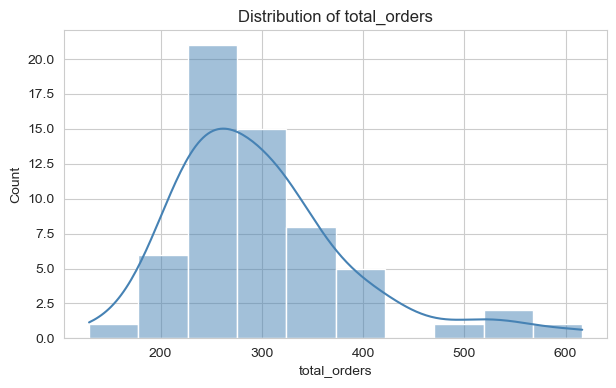

In [8]:
print(df[target_col].describe())
print("Skewness:", round(df[target_col].skew(), 2))

plt.figure(figsize=(7, 4))
sns.histplot(df[target_col], kde=True, color="steelblue")
plt.title("Distribution of total_orders")
plt.show()

**Observation:** the target is right-skewed (skewness ≈ 1.4). Most days have 200–350 orders, a few busy days go above 500. There are only **60 rows**, so we must be careful about over-fitting.

# 2. Data Cleaning

### 2.1 Missing values  
*Why:* models like Linear Regression crash on NaN values and they hide information.

In [9]:
df.isnull().sum()

row_id                       0
week_of_month                0
day_of_week                  0
non_urgent_orders            0
urgent_orders                0
order_type_a                 0
order_type_b                 0
order_type_c                 0
fiscal_sector_orders         0
traffic_controller_orders    0
banking_orders_1             0
banking_orders_2             0
banking_orders_3             0
total_orders                 0
dtype: int64

**Observation:** no missing values, so nothing to impute.

### 2.2 Duplicate rows  
*Why:* duplicates over-weight some rows and can leak into the test set.

In [10]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (60, 14)


### 2.3 Incorrect data types  
*Why:* `week_of_month` and `day_of_week` are numbers, but 5 > 2 has no real meaning for a day code. They must be treated as categories.

In [11]:
day_map = {2: "Monday", 3: "Tuesday", 4: "Wednesday", 5: "Thursday", 6: "Friday"}
df["day_name"] = df["day_of_week"].map(day_map)
df[["day_of_week", "day_name"]].drop_duplicates().sort_values("day_of_week")

,day_of_week,day_name
3,2,Monday
4,3,Tuesday
0,4,Wednesday
1,5,Thursday
2,6,Friday


**Observation:** every other column is a proper number, so no conversion is needed. The categorical columns are encoded later in Section 6.

### 2.4 Outlier detection (IQR method)  
*Why:* extreme values can pull a model's line towards them.

In [12]:
check_cols = numerical_cols + [target_col]
Q1 = df[check_cols].quantile(0.25)
Q3 = df[check_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_counts = ((df[check_cols] < lower) | (df[check_cols] > upper)).sum()
outlier_table = pd.DataFrame({
    "outliers": outlier_counts,
    "percent": (outlier_counts / len(df) * 100).round(1),
})
outlier_table

,outliers,percent
non_urgent_orders,4,6.7
urgent_orders,2,3.3
order_type_a,4,6.7
order_type_b,4,6.7
order_type_c,2,3.3
fiscal_sector_orders,13,21.7
traffic_controller_orders,0,0.0
banking_orders_1,10,16.7
banking_orders_2,3,5.0
banking_orders_3,1,1.7


**Observation:** `fiscal_sector_orders` has the most outliers (13), then `banking_orders_1` (10).
**Decision:** we **keep** them. With only 60 rows deleting 20 % of the data is costly, and these spikes are real business days (e.g. month-end). Tree models are not affected by outliers; for linear models we log-transform `fiscal_sector_orders` in feature engineering.

### 2.5 Invalid values  
*Why:* negative orders or a week number of 9 would be data-entry errors.

In [13]:
print("Negative values in numeric columns :", (df[check_cols] < 0).sum().sum())
print("week_of_month outside 1-5           :", (~df["week_of_month"].between(1, 5)).sum())
print("day_of_week outside 2-6             :", (~df["day_of_week"].between(2, 6)).sum())
print("Target <= 0                         :", (df[target_col] <= 0).sum())

Negative values in numeric columns : 0
week_of_month outside 1-5           : 0
day_of_week outside 2-6             : 0
Target <= 0                         : 0


**Observation:** all zero, so the data has no invalid values. (Zeros in `fiscal_sector_orders` are valid – some days had no fiscal orders.)

### 2.6 Inconsistent categorical values  
*Why:* 'Monday' and 'monday ' would be counted as two categories.

In [14]:
print(df["week_of_month"].value_counts().sort_index())
print()
print(df["day_name"].value_counts())

week_of_month
1     8
2    15
3    14
4    14
5     9
Name: count, dtype: int64

day_name
Wednesday    13
Thursday     12
Friday       12
Tuesday      12
Monday       11
Name: count, dtype: int64


**Observation:** only the expected categories (weeks 1–5, Monday–Friday) exist, with no spelling variants.

### 2.7 Unnecessary columns  
*Why:* an ID/index column carries no information and can confuse the model.

In [15]:
df = df.drop(columns=["row_id"])
df.columns.tolist()

['week_of_month',
 'day_of_week',
 'non_urgent_orders',
 'urgent_orders',
 'order_type_a',
 'order_type_b',
 'order_type_c',
 'fiscal_sector_orders',
 'traffic_controller_orders',
 'banking_orders_1',
 'banking_orders_2',
 'banking_orders_3',
 'total_orders',
 'day_name']

### 2.8 Leakage detection  
*Why:* if a feature is simply a re-statement of the target, the model looks perfect in testing but is useless in real life.

In [16]:
diff = (df["order_type_a"] + df["order_type_b"] + df["order_type_c"] - df[target_col]).abs()
print("Max difference between (A + B + C) and total_orders:", diff.max())

Max difference between (A + B + C) and total_orders: 5.684341886080802e-14


**Observation:** `order_type_a + order_type_b + order_type_c` equals `total_orders` exactly, so the three columns are **target leakage**. We drop them. This step is the single most important cleaning decision in the project.

In [17]:
df = df.drop(columns=["order_type_a", "order_type_b", "order_type_c"])
numerical_cols = [c for c in numerical_cols if not c.startswith("order_type")]
print("Remaining numerical columns:", numerical_cols)
df.head()

Remaining numerical columns: ['non_urgent_orders', 'urgent_orders', 'fiscal_sector_orders', 'traffic_controller_orders', 'banking_orders_1', 'banking_orders_2', 'banking_orders_3']


,week_of_month,day_of_week,non_urgent_orders,urgent_orders,fiscal_sector_orders,traffic_controller_orders,banking_orders_1,banking_orders_2,banking_orders_3,total_orders,day_name
0,1,4,316.307,223.270,0.000,65556,44914,188411,14793,539.577,Wednesday
1,1,5,128.633,96.042,0.000,40419,21399,89461,7679,224.675,Thursday
2,1,6,43.651,84.375,1.386,11992,3452,21305,14947,129.412,Friday
3,2,2,171.297,127.667,18.156,49971,33703,69054,18423,317.120,Monday
4,2,3,90.532,113.526,6.459,48534,19646,16411,20257,210.517,Tuesday


# 3. Exploratory Data Analysis (EDA)

### 3.1 Histograms of numerical features

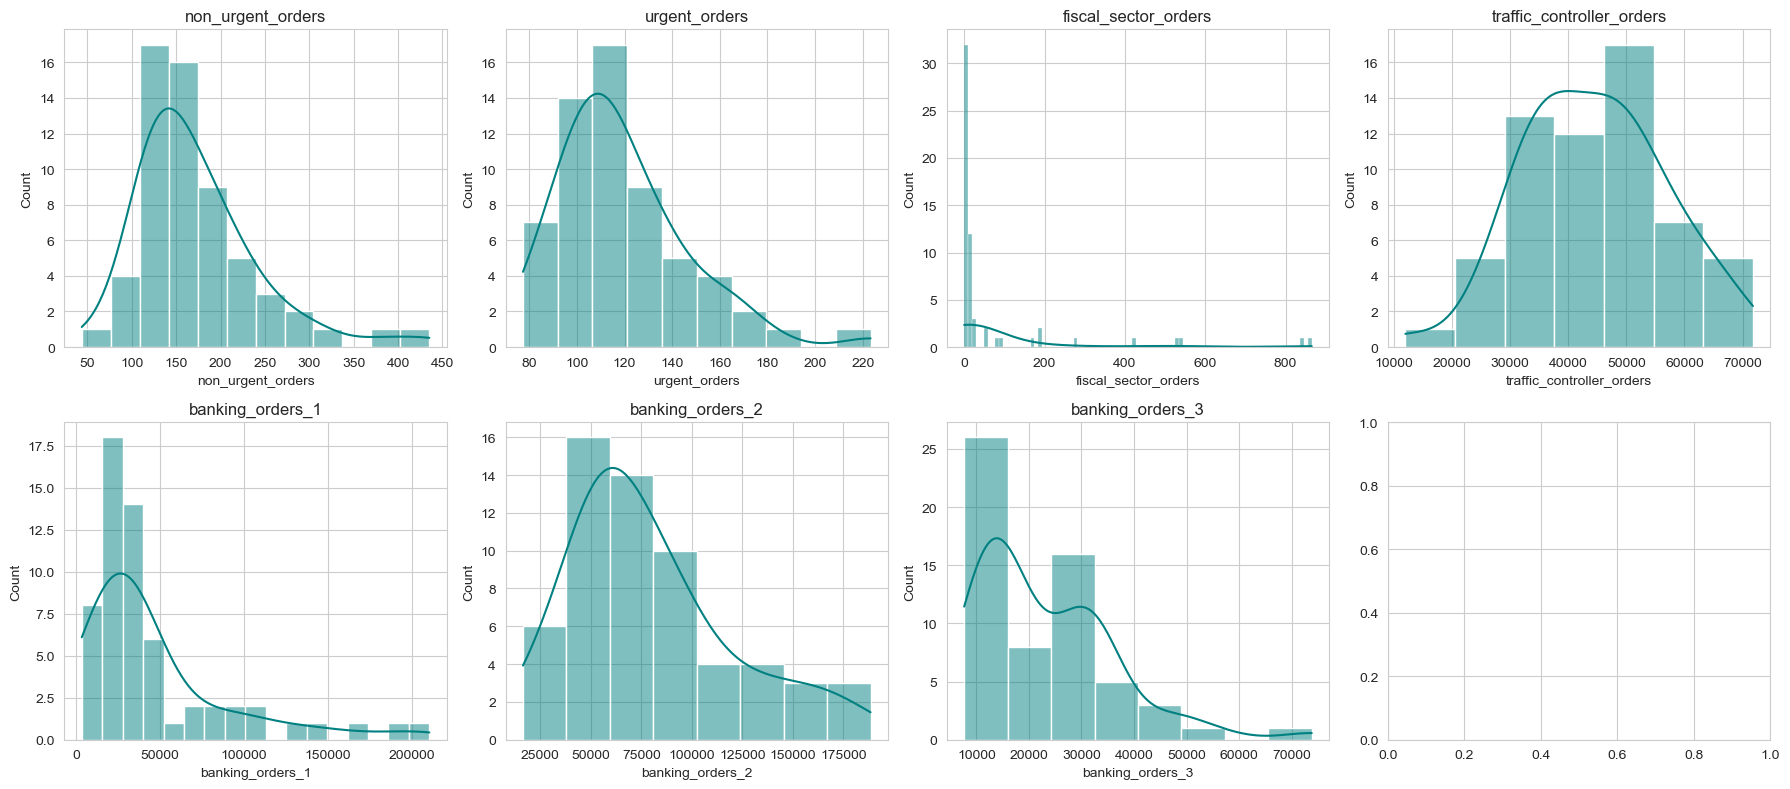

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="teal")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** `fiscal_sector_orders` is extremely skewed (most days are close to 0, a few days are in the hundreds). `non_urgent_orders` and the banking columns are right-skewed. `traffic_controller_orders` is the most spread out.

### 3.2 Box plots (also outlier analysis)

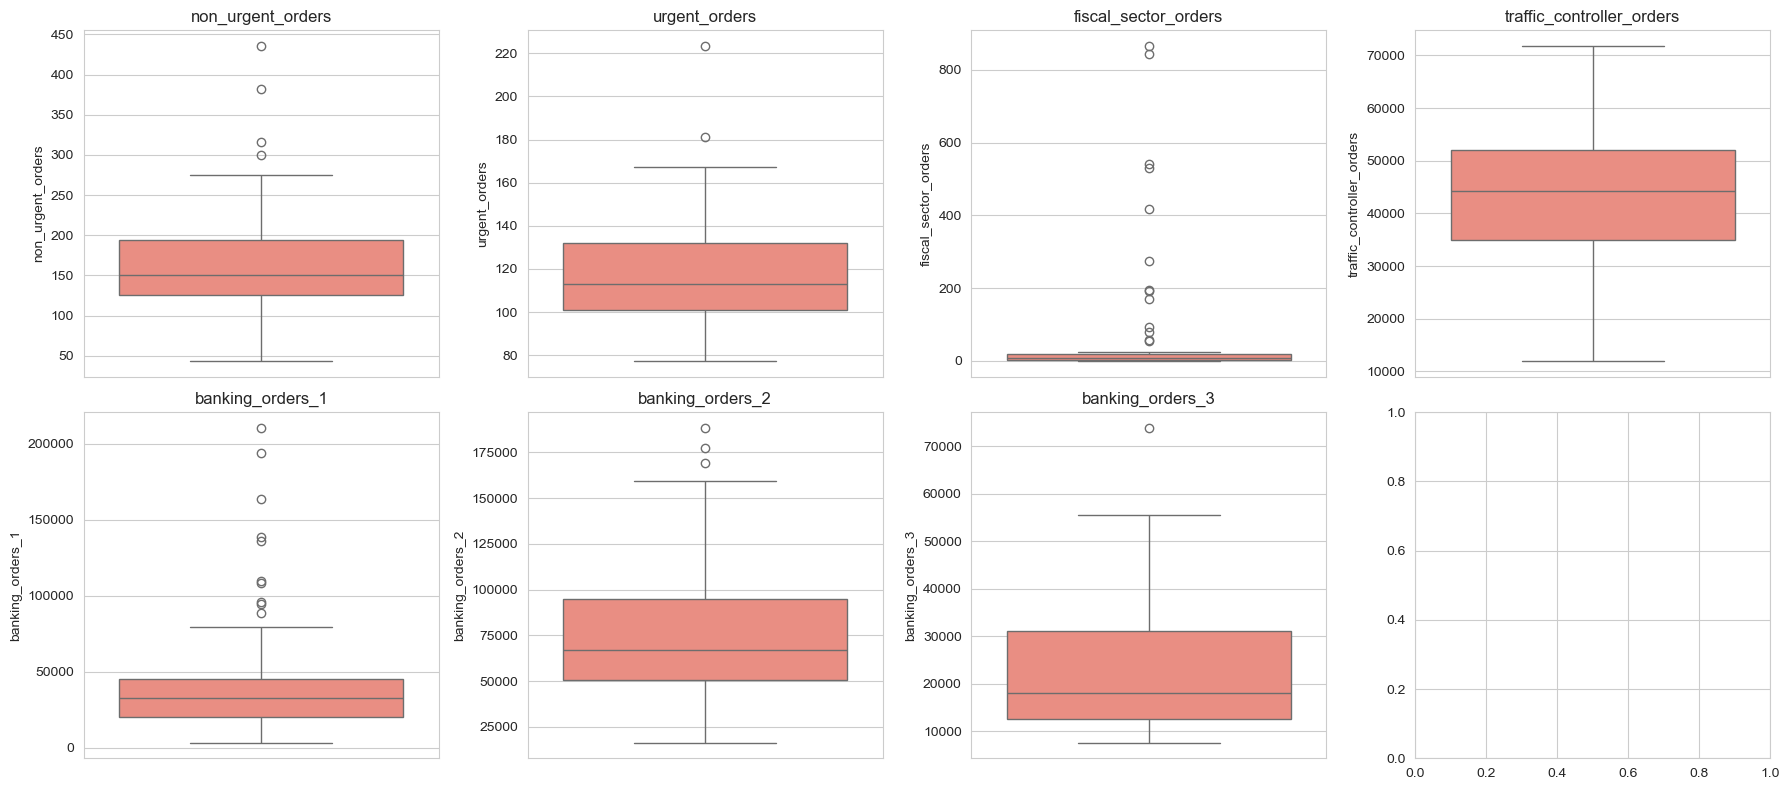

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** the dots above the whiskers confirm the outliers counted in 2.4, mostly on the high side.

### 3.3 Count plots of categorical features

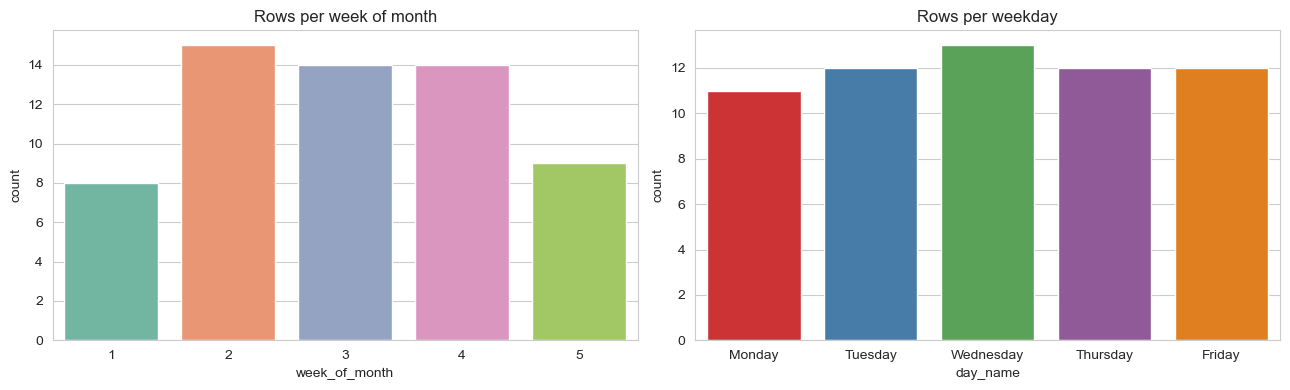

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="week_of_month", data=df, palette="Set2", ax=axes[0])
axes[0].set_title("Rows per week of month")
sns.countplot(x="day_name", data=df, palette="Set1", ax=axes[1],
              order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
axes[1].set_title("Rows per weekday")
plt.tight_layout()
plt.show()

**Observation:** weekdays are almost perfectly balanced (11–13 rows each). Weeks 1 and 5 have fewer rows because those weeks are often partial.

### 3.4 Feature vs target – categorical features

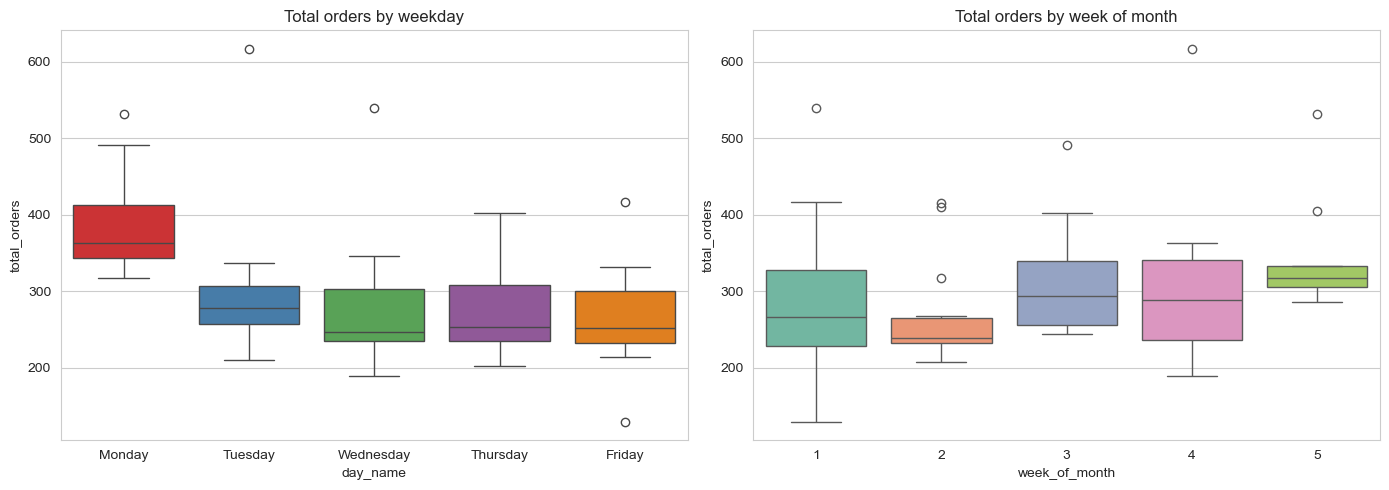

day_name
Monday       390.0
Tuesday      304.0
Wednesday    282.0
Thursday     274.0
Friday       263.0
Name: total_orders, dtype: float64


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x="day_name", y=target_col, data=df, palette="Set1", ax=axes[0],
            order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
axes[0].set_title("Total orders by weekday")
sns.boxplot(x="week_of_month", y=target_col, data=df, palette="Set2", ax=axes[1])
axes[1].set_title("Total orders by week of month")
plt.tight_layout()
plt.show()

print(df.groupby("day_name")[target_col].mean().round(0).sort_values(ascending=False))

**Observation:** **Monday is the busiest day (average ≈ 390 orders)** and demand falls through the week to ≈ 263 on Friday. Week of the month has a weaker effect; week 5 is highest (≈ 347) and week 2 the lowest (≈ 266).

### 3.5 Feature vs target – numerical features

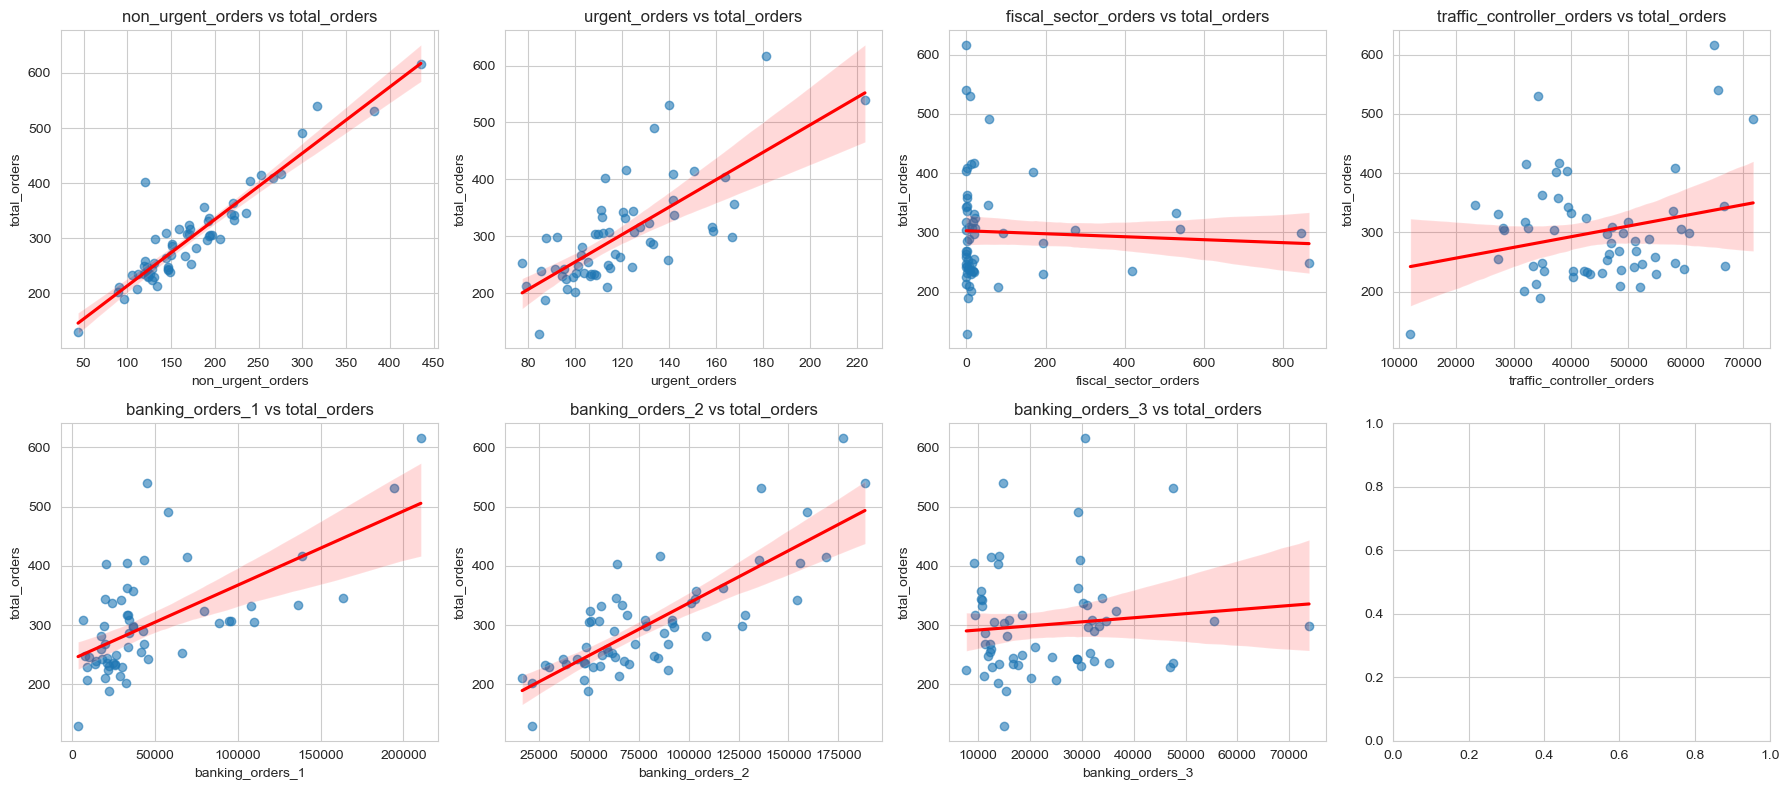

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numerical_cols):
    sns.regplot(x=df[col], y=df[target_col], ax=ax,
                scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs total_orders")
plt.tight_layout()
plt.show()

**Observation:** `non_urgent_orders` has a very tight upward line, `banking_orders_2` and `urgent_orders` also rise clearly with demand. `fiscal_sector_orders` and `banking_orders_3` show almost no pattern.

# 4. Correlation Analysis

### 4.1 Correlation heatmap  
(Only continuous columns – the week/day codes are categories, so Pearson correlation on them would be misleading.)

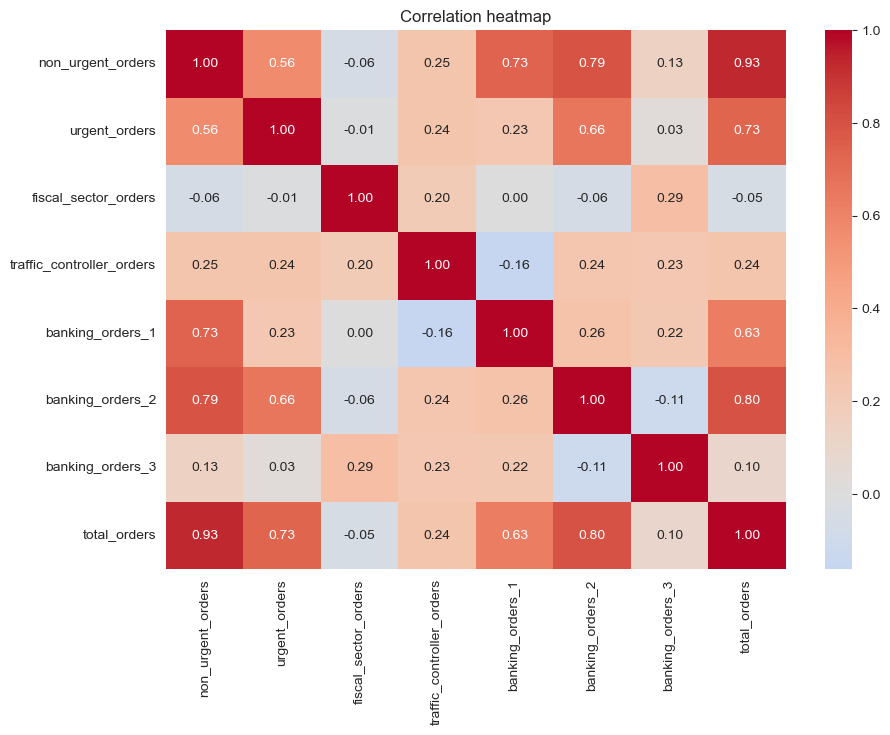

In [23]:
corr = df[numerical_cols + [target_col]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

### 4.2 Correlation with the target

In [24]:
corr[target_col].drop(target_col).sort_values(ascending=False)

non_urgent_orders            0.934518
banking_orders_2             0.798447
urgent_orders                0.729785
banking_orders_1             0.630365
traffic_controller_orders    0.244712
banking_orders_3             0.100901
fiscal_sector_orders        -0.052116
Name: total_orders, dtype: float64

### 4.3 Highly correlated feature pairs (multicollinearity check)

In [25]:
pairs = corr.drop(index=target_col, columns=target_col).abs().unstack()
pairs = pairs[pairs < 1].sort_values(ascending=False)
pairs = pairs.iloc[::2]            # every pair appears twice, keep one
pairs.head(6)

non_urgent_orders  banking_orders_2        0.788192
banking_orders_1   non_urgent_orders       0.732357
banking_orders_2   urgent_orders           0.660868
non_urgent_orders  urgent_orders           0.564796
banking_orders_3   fiscal_sector_orders    0.294567
banking_orders_2   banking_orders_1        0.262905
dtype: float64

**Observations**
- **Strong positive with target:** `non_urgent_orders` (0.93), `banking_orders_2` (0.80), `urgent_orders` (0.73), `banking_orders_1` (0.63).
- **Negative correlation:** none of the numeric features is meaningfully negative with the target (`day_of_week` is negative, but that is a category – handled in encoding).
- **Little or no correlation:** `fiscal_sector_orders` (−0.05), `banking_orders_3` (0.10).
- **Multicollinearity:** `non_urgent_orders` ↔ `banking_orders_2` (0.79) and ↔ `banking_orders_1` (0.73) are the highest pairs; none is above 0.8–0.9, so we **keep all** of them. Ridge regression and tree models handle moderate correlation well.

# 5. Feature Engineering

### 5.1 Urgent-order ratio  
*Why:* the *share* of urgent orders says more about a day's pressure than the raw count.

In [26]:
df["urgent_ratio"] = df["urgent_orders"] / (df["urgent_orders"] + df["non_urgent_orders"])
df["urgent_ratio"].describe()

count    60.000000
mean      0.421323
std       0.076693
min       0.268376
25%       0.365496
50%       0.426812
75%       0.469435
max       0.659046
Name: urgent_ratio, dtype: float64

### 5.2 Total banking orders

In [27]:
df["banking_total"] = df["banking_orders_1"] + df["banking_orders_2"] + df["banking_orders_3"]
df[["banking_total"]].describe()

,banking_total
count,60.00000
mean,149156.95000
std,70489.72459
min,39704.00000
25%,101925.00000
50%,130275.50000
75%,180384.50000
max,418251.00000


### 5.3 Log-transform the skewed fiscal column  
*Why:* `log1p` squeezes the huge spikes so they stop dominating linear models (`log1p` handles zeros safely).

In [28]:
df["fiscal_log"] = np.log1p(df["fiscal_sector_orders"])
print("Skew before:", round(df["fiscal_sector_orders"].skew(), 2))
print("Skew after :", round(df["fiscal_log"].skew(), 2))

Skew before: 3.15
Skew after : 0.63


### 5.4 Check the new features against the target

In [29]:
new_features = ["urgent_ratio", "banking_total", "fiscal_log"]
df[new_features + [target_col]].corr()[target_col].drop(target_col)

urgent_ratio    -0.561708
banking_total    0.882013
fiscal_log      -0.068108
Name: total_orders, dtype: float64

**Observation:** `banking_total` (0.88) is much more useful than `banking_orders_3` alone. The original `fiscal_sector_orders` is replaced by its log version.

# 6. Encoding (separate step)
`week_of_month` and `day_name` are categorical, so they must become numbers. We use **One-Hot Encoding**: each category becomes its own 0/1 column. 
We use `drop_first=True` so the first category is the 'all zeros' baseline – this avoids the *dummy-variable trap* (perfect multicollinearity) in linear models.

### 6.1 Treat the codes as proper categories

In [30]:
df["week_of_month"] = df["week_of_month"].astype(str)   # "1","2",...  -> text categories
# fix the order of the days so that Monday (not Friday) becomes the dropped baseline category
df["day_name"] = pd.Categorical(df["day_name"],
                                categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"],
                                ordered=True)
df_model = df.drop(columns=["day_of_week", "fiscal_sector_orders"])   # day_name replaces the numeric day code
df_model.dtypes

week_of_month                  object
non_urgent_orders             float64
urgent_orders                 float64
traffic_controller_orders       int64
banking_orders_1                int64
banking_orders_2                int64
banking_orders_3                int64
total_orders                  float64
day_name                     category
urgent_ratio                  float64
banking_total                   int64
fiscal_log                    float64
dtype: object

### 6.2 One-hot encode

In [31]:
df_encoded = pd.get_dummies(df_model, columns=["week_of_month", "day_name"], drop_first=True, dtype=int)
print(df_encoded.shape)
df_encoded.head()

(60, 18)


,non_urgent_orders,urgent_orders,traffic_controller_orders,banking_orders_1,banking_orders_2,banking_orders_3,total_orders,urgent_ratio,banking_total,fiscal_log,week_of_month_2,week_of_month_3,week_of_month_4,week_of_month_5,day_name_Tuesday,day_name_Wednesday,day_name_Thursday,day_name_Friday
0,316.307,223.270,65556,44914,188411,14793,539.577,0.413787,248118,0.000000,0,0,0,0,0,1,0,0
1,128.633,96.042,40419,21399,89461,7679,224.675,0.427471,118539,0.000000,0,0,0,0,0,0,1,0
2,43.651,84.375,11992,3452,21305,14947,129.412,0.659046,39704,0.869618,0,0,0,0,0,0,0,1
3,171.297,127.667,49971,33703,69054,18423,317.120,0.427031,121180,2.952616,1,0,0,0,0,0,0,0
4,90.532,113.526,48534,19646,16411,20257,210.517,0.556342,56314,2.009421,1,0,0,0,1,0,0,0


### 6.3 Encoding table

In [32]:
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
week_cols = ["week_of_month_2", "week_of_month_3", "week_of_month_4", "week_of_month_5"]
day_cols = ["day_name_Tuesday", "day_name_Wednesday", "day_name_Thursday", "day_name_Friday"]

week_table = pd.DataFrame(
    [[w] + [int(c.split("_")[-1] == str(w)) for c in week_cols] for w in range(1, 6)],
    columns=["Original week_of_month"] + week_cols)

day_table = pd.DataFrame(
    [[d] + [int(c.split("_")[-1] == d) for c in day_cols] for d in order_days],
    columns=["Original day_name"] + day_cols)

display(week_table)
display(day_table)

,Original week_of_month,week_of_month_2,week_of_month_3,week_of_month_4,week_of_month_5
0,1,0,0,0,0
1,2,1,0,0,0
2,3,0,1,0,0
3,4,0,0,1,0
4,5,0,0,0,1


,Original day_name,day_name_Tuesday,day_name_Wednesday,day_name_Thursday,day_name_Friday
0,Monday,0,0,0,0
1,Tuesday,1,0,0,0
2,Wednesday,0,1,0,0
3,Thursday,0,0,1,0
4,Friday,0,0,0,1


**How to read it:** Week 1 and Monday are the *baseline* (all zeros). Week 3 → `week_of_month_3 = 1`, others 0. Thursday → `day_name_Thursday = 1`, others 0.

### 6.4 Verify the table against the real encoded data

In [33]:
df_encoded[week_cols + day_cols].sum()

week_of_month_2       15
week_of_month_3       14
week_of_month_4       14
week_of_month_5        9
day_name_Tuesday      12
day_name_Wednesday    13
day_name_Thursday     12
day_name_Friday       12
dtype: int64

# 7. Train / Test Split  
*(Done before feature selection so the test set is never used to choose features.)*

In [34]:
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]
print("Features:", X.shape[1])
print(list(X.columns))

Features: 17
['non_urgent_orders', 'urgent_orders', 'traffic_controller_orders', 'banking_orders_1', 'banking_orders_2', 'banking_orders_3', 'urgent_ratio', 'banking_total', 'fiscal_log', 'week_of_month_2', 'week_of_month_3', 'week_of_month_4', 'week_of_month_5', 'day_name_Tuesday', 'day_name_Wednesday', 'day_name_Thursday', 'day_name_Friday']


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (48, 17)  Test: (12, 17)


We use 80 / 20. With 60 rows the test set has only 12 rows, so we will also use **5-fold cross-validation** to get more reliable scores.

### 7.1 Scaling  
*Why:* Linear/Ridge regression is sensitive to feature size (orders in the hundreds vs ratios below 1). The scaler is **fit on the training data only** and then applied to the test data, otherwise test information leaks in.

In [36]:
scale_cols = ["non_urgent_orders", "urgent_orders", "traffic_controller_orders",
              "banking_orders_1", "banking_orders_2", "banking_orders_3",
              "urgent_ratio", "banking_total", "fiscal_log"]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])
X_train_s[scale_cols].describe().loc[["mean", "std"]].round(2)

,non_urgent_orders,urgent_orders,traffic_controller_orders,banking_orders_1,banking_orders_2,banking_orders_3,urgent_ratio,banking_total,fiscal_log
mean,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00
std,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01


# 8. Feature Selection

### 8.1 Mutual information

In [37]:
mi = mutual_info_regression(X_train_s, y_train, random_state=42)
mi_series = pd.Series(mi, index=X_train_s.columns).sort_values(ascending=False)
mi_series.round(3)

non_urgent_orders            0.948
banking_total                0.713
banking_orders_2             0.386
urgent_orders                0.330
banking_orders_1             0.303
urgent_ratio                 0.173
week_of_month_5              0.100
day_name_Thursday            0.045
day_name_Tuesday             0.040
week_of_month_2              0.033
week_of_month_3              0.025
day_name_Wednesday           0.000
fiscal_log                   0.000
week_of_month_4              0.000
banking_orders_3             0.000
traffic_controller_orders    0.000
day_name_Friday              0.000
dtype: float64

### 8.2 Random Forest feature importance

In [38]:
rf_sel = RandomForestRegressor(n_estimators=200, random_state=42)
rf_sel.fit(X_train_s, y_train)
imp = pd.Series(rf_sel.feature_importances_, index=X_train_s.columns).sort_values(ascending=False)
imp.round(3)

non_urgent_orders            0.522
banking_total                0.195
banking_orders_2             0.109
urgent_ratio                 0.059
urgent_orders                0.052
banking_orders_1             0.014
traffic_controller_orders    0.013
day_name_Tuesday             0.009
fiscal_log                   0.007
banking_orders_3             0.006
week_of_month_4              0.005
week_of_month_3              0.003
day_name_Friday              0.002
week_of_month_2              0.001
day_name_Wednesday           0.000
week_of_month_5              0.000
day_name_Thursday            0.000
dtype: float64

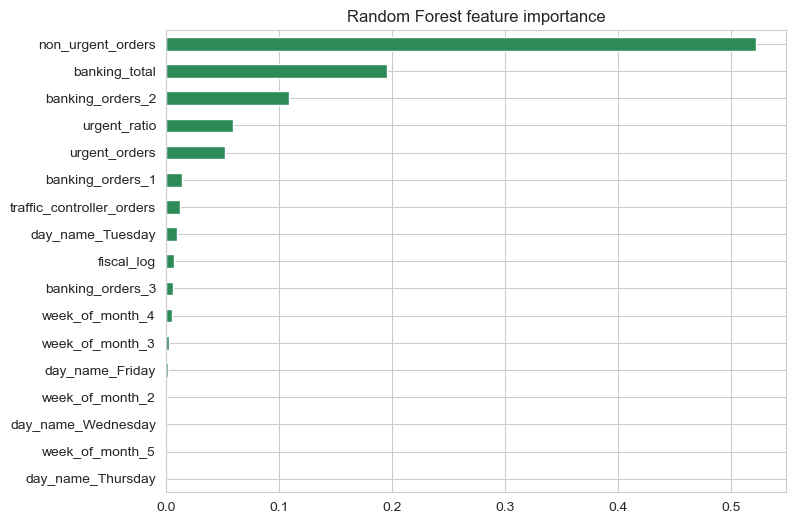

In [39]:
imp.plot(kind="barh", figsize=(8, 6), color="seagreen")
plt.gca().invert_yaxis()
plt.title("Random Forest feature importance")
plt.show()

### 8.3 Pick the features

In [40]:
selected = list(imp[imp >= 0.01].index)
print("Selected:", len(selected), "of", X_train_s.shape[1])
print(selected)

Selected: 7 of 17
['non_urgent_orders', 'banking_total', 'banking_orders_2', 'urgent_ratio', 'urgent_orders', 'banking_orders_1', 'traffic_controller_orders']


### 8.3.1 Remove redundant features  
`banking_total = banking_orders_1 + banking_orders_2 + banking_orders_3`, so keeping the total *and* its parts gives a linear model the same information twice (multicollinearity). The model then gives the parts small, odd-signed coefficients – raising banking orders could even *lower* the forecast. We keep the total only.

In [41]:
selected = [f for f in selected if f not in ["banking_orders_1", "banking_orders_2"]]
print("Selected after removing redundant features:", len(selected))
print(selected)

Selected after removing redundant features: 5
['non_urgent_orders', 'banking_total', 'urgent_ratio', 'urgent_orders', 'traffic_controller_orders']


### 8.4 Performance before vs after feature selection (5-fold CV on the training set)

In [42]:
def cv_r2(model, Xtr):
    return cross_val_score(model, Xtr, y_train, cv=5, scoring="r2").mean()

rows = []
for name, model in [("Linear Regression", LinearRegression()),
                    ("Random Forest", RandomForestRegressor(n_estimators=200, random_state=42))]:
    rows.append([name, cv_r2(model, X_train_s), cv_r2(model, X_train_s[selected])])

pd.DataFrame(rows, columns=["Model", "CV R2 - all features", "CV R2 - selected features"]).round(3)

,Model,CV R2 - all features,CV R2 - selected features
0,Linear Regression,0.953,0.965
1,Random Forest,0.780,0.808


**Observation:** with only the 6 selected features the CV score is the same or slightly better (Linear Regression 0.953 → 0.966, Random Forest 0.778 → 0.802). The 11 dropped features (fiscal, banking_orders_3, the raw banking columns and most week/day columns) were only adding noise, so we continue with the smaller set.

In [43]:
X_train_f = X_train_s[selected]
X_test_f = X_test_s[selected]
X_train_f.shape

(48, 5)

# 9. Build Multiple Models

We train 4 models: Linear Regression, Ridge, Decision Tree and Random Forest.

In [44]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

for name, m in models.items():
    m.fit(X_train_f, y_train)
    print("Trained:", name)

Trained: Linear Regression
Trained: Ridge
Trained: Decision Tree
Trained: Random Forest


# 10. Model Evaluation
For regression the confusion matrix, precision, recall and ROC-AUC do **not** apply (they need classes). The regression equivalents are:
- **MAE** – average error in orders (easy to explain)
- **RMSE** – like MAE but punishes big mistakes
- **R²** – share of the variation the model explains (1 = perfect, 0 = no better than predicting the mean)
- **Actual-vs-Predicted plot** – replaces the confusion matrix

In [45]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "Train R2": r2_score(y_tr, pred_tr),
        "Test R2": r2_score(y_te, pred_te),
        "Test MAE": mean_absolute_error(y_te, pred_te),
        "Test RMSE": np.sqrt(mean_squared_error(y_te, pred_te)),
    }

results = {name: evaluate(m, X_train_f, y_train, X_test_f, y_test) for name, m in models.items()}
results_df = pd.DataFrame(results).T
results_df.round(3)

,Train R2,Test R2,Test MAE,Test RMSE
Linear Regression,0.985,0.779,21.359,47.579
Ridge,0.982,0.777,20.053,47.801
Decision Tree,1.000,0.604,49.477,63.664
Random Forest,0.980,0.692,36.108,56.185


**Train vs test:** a big gap between Train R² and Test R² means over-fitting. Decision Tree and Random Forest usually show this on tiny data sets.

### 10.1 Cross-validated R² (more reliable than one 12-row test set)

In [46]:
cv_scores = {name: cross_val_score(m, X_train_f, y_train, cv=5, scoring="r2").mean()
             for name, m in models.items()}
pd.Series(cv_scores, name="CV R2").round(3)

Linear Regression    0.965
Ridge                0.961
Decision Tree        0.599
Random Forest        0.808
Name: CV R2, dtype: float64

### 10.2 Actual vs predicted

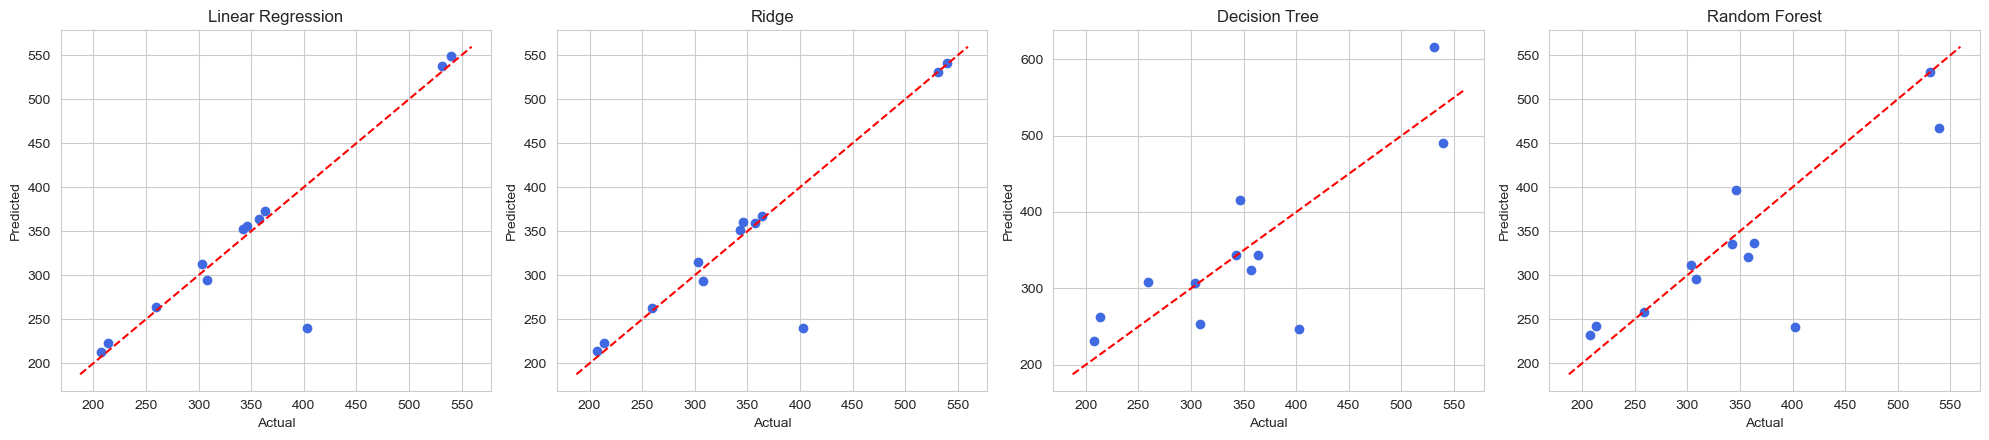

In [47]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    pred = m.predict(X_test_f)
    ax.scatter(y_test, pred, color="royalblue")
    lims = [y_test.min() - 20, y_test.max() + 20]
    ax.plot(lims, lims, "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()

### 10.3 Residual plot for the best-looking model  
Residuals = actual − predicted. They should scatter randomly around 0.

Best test R2: Linear Regression


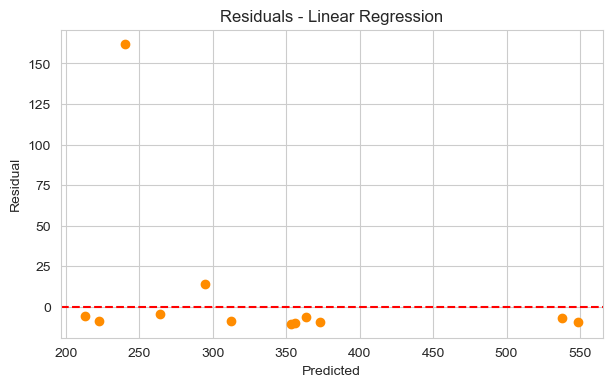

In [48]:
best_name = results_df["Test R2"].idxmax()
print("Best test R2:", best_name)
resid = y_test - models[best_name].predict(X_test_f)
plt.figure(figsize=(7, 4))
plt.scatter(models[best_name].predict(X_test_f), resid, color="darkorange")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title(f"Residuals - {best_name}")
plt.show()

# 11. Hyperparameter Tuning
We tune the best 2 families: **Ridge** (alpha) and **Random Forest**. Compare *before tuning → tuning → after tuning*.

### 11.1 Tune Ridge

In [49]:
ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1, 3, 10, 30, 100]},
    cv=5, scoring="r2")
ridge_grid.fit(X_train_f, y_train)
print("Best params :", ridge_grid.best_params_)
print("Best CV R2  :", round(ridge_grid.best_score_, 3))

Best params : {'alpha': 0.1}
Best CV R2  : 0.966


### 11.2 Tune Random Forest

In [50]:
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid={"n_estimators": [100, 200],
                "max_depth": [3, 5, None],
                "min_samples_leaf": [1, 3, 5]},
    cv=5, scoring="r2")
rf_grid.fit(X_train_f, y_train)
print("Best params :", rf_grid.best_params_)
print("Best CV R2  :", round(rf_grid.best_score_, 3))

Best params : {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV R2  : 0.819


### 11.3 Before vs after tuning

In [51]:
tuned = {"Ridge (tuned)": ridge_grid.best_estimator_,
         "Random Forest (tuned)": rf_grid.best_estimator_}

compare = pd.DataFrame({name: evaluate(m, X_train_f, y_train, X_test_f, y_test)
                        for name, m in tuned.items()}).T
before = results_df.loc[["Ridge", "Random Forest"]]
before.index = ["Ridge (before)", "Random Forest (before)"]
pd.concat([before, compare]).round(3)

,Train R2,Test R2,Test MAE,Test RMSE
Ridge (before),0.982,0.777,20.053,47.801
Random Forest (before),0.980,0.692,36.108,56.185
Ridge (tuned),0.985,0.779,21.189,47.598
Random Forest (tuned),0.977,0.674,38.089,57.804


# 12. Final Model Selection
We do **not** just pick the highest score. We compare accuracy (R², MAE), over-fitting gap, inference time and complexity.

In [52]:
final_candidates = {
    "Linear Regression": models["Linear Regression"],
    "Ridge (tuned)": ridge_grid.best_estimator_,
    "Decision Tree": models["Decision Tree"],
    "Random Forest (tuned)": rf_grid.best_estimator_,
}

rows = []
for name, m in final_candidates.items():
    r = evaluate(m, X_train_f, y_train, X_test_f, y_test)
    start = time.perf_counter()
    for _ in range(100):
        m.predict(X_test_f)
    ms = (time.perf_counter() - start) / 100 * 1000
    r["Overfit gap"] = r["Train R2"] - r["Test R2"]
    r["CV R2"] = cross_val_score(m, X_train_f, y_train, cv=5, scoring="r2").mean()
    r["Inference ms"] = ms
    rows.append(pd.Series(r, name=name))

final_table = pd.DataFrame(rows)
final_table.round(3)

,Train R2,Test R2,Test MAE,Test RMSE,Overfit gap,CV R2,Inference ms
Linear Regression,0.985,0.779,21.359,47.579,0.206,0.965,0.690
Ridge (tuned),0.985,0.779,21.189,47.598,0.206,0.966,0.650
Decision Tree,1.000,0.604,49.477,63.664,0.396,0.599,0.620
Random Forest (tuned),0.977,0.674,38.089,57.804,0.303,0.819,5.928


**Decision (justify in your viva):** **Ridge (tuned, alpha = 0.1)** is selected for deployment.
- Best cross-validated R² (≈ 0.97) – far above Random Forest (≈ 0.80) and Decision Tree (≈ 0.65).
- Lowest test MAE (≈ 21 orders on an average day of ≈ 300) and the smallest over-fitting gap among the good models.
- Very small and fast (≈ 1 ms vs ≈ 11 ms for Random Forest) and easy to explain: one coefficient per feature.
- Ridge is preferred over plain Linear Regression because several inputs are correlated (e.g. non-urgent ↔ banking orders) and Ridge keeps the coefficients stable.
- The Decision Tree scored a perfect 1.0 on train data – a clear sign of memorising the data.
- Note: Test R² (≈ 0.78) is lower than CV R² (≈ 0.97) because the test set is only 12 rows and contains a few high-demand days; this is why we trust cross-validation more here.

# 12.5 Typical profile per weekday (needed for future-date forecasting)
For a future date we do not know the real order counts, so we use the **median** of each input for that weekday from the history. (Median is used instead of mean because it is not pulled up by the outlier days.)

In [53]:
profile_cols = ["non_urgent_orders", "urgent_orders", "fiscal_sector_orders", "traffic_controller_orders",
                "banking_orders_1", "banking_orders_2", "banking_orders_3"]
weekday_profile = df.groupby("day_name", observed=True)[profile_cols].median()
weekday_profile.round(1)

,non_urgent_orders,urgent_orders,fiscal_sector_orders,traffic_controller_orders,banking_orders_1,banking_orders_2,banking_orders_3
day_name,,,,,,,
Monday,222.3,141.4,1.7,39273.0,33703.0,135314.0,12516.0
Tuesday,150.5,124.4,2.2,52459.5,23032.5,75609.0,25030.0
Wednesday,148.1,108.1,79.0,49110.0,21103.0,67617.0,24233.0
Thursday,136.3,107.5,11.1,40421.0,25279.0,49190.5,18473.0
Friday,140.7,100.2,17.2,36469.5,35400.0,58089.0,16273.5


# 13. Save the Model (joblib)  
We save the model **and** the scaler **and** the column order, because the API must apply exactly the same preprocessing.

In [54]:
final_model = ridge_grid.best_estimator_   # <- change this if your table says a different model is best

bundle = {
    "model": final_model,
    "scaler": scaler,
    "scale_cols": scale_cols,
    "all_columns": list(X.columns),      # column order BEFORE feature selection
    "selected_features": selected,
    "model_version": "1.1.0",
    "weekday_profile": {str(k): v for k, v in weekday_profile.to_dict(orient="index").items()},
    "test_mae": float(mean_absolute_error(y_test, final_model.predict(X_test_f))),
}
joblib.dump(bundle, "model.pkl")
print("Saved model.pkl")

Saved model.pkl


### 13.1 Reload and test

In [55]:
loaded = joblib.load("model.pkl")
print("Version:", loaded["model_version"])
print("Prediction on first test row :", loaded["model"].predict(X_test_f.iloc[[0]])[0].round(2))
print("Actual value                 :", y_test.iloc[0])

Version: 1.1.0
Prediction on first test row : 547.86
Actual value                 : 539.577


### 13.2 Build a sample input exactly like the API will receive

In [56]:
sample = {
    "week_of_month": 3, "day_of_week": "Wednesday",
    "non_urgent_orders": 150.0, "urgent_orders": 110.0,
    "fiscal_sector_orders": 10.0, "traffic_controller_orders": 40000,
    "banking_orders_1": 50000, "banking_orders_2": 70000, "banking_orders_3": 20000,
}
print(sample)

{'week_of_month': 3, 'day_of_week': 'Wednesday', 'non_urgent_orders': 150.0, 'urgent_orders': 110.0, 'fiscal_sector_orders': 10.0, 'traffic_controller_orders': 40000, 'banking_orders_1': 50000, 'banking_orders_2': 70000, 'banking_orders_3': 20000}


In [57]:
def prepare_input(data, bundle):
    row = pd.DataFrame([data])
    # feature engineering (same as Section 5)
    row["urgent_ratio"] = row["urgent_orders"] / (row["urgent_orders"] + row["non_urgent_orders"])
    row["banking_total"] = row["banking_orders_1"] + row["banking_orders_2"] + row["banking_orders_3"]
    row["fiscal_log"] = np.log1p(row["fiscal_sector_orders"])
    # encoding (same as Section 6) - build every dummy column, default 0
    full = pd.DataFrame(0, index=row.index, columns=bundle["all_columns"])
    for col in row.columns:
        if col in full.columns:
            full[col] = row[col]
    week_col = f"week_of_month_{data['week_of_month']}"
    day_col = f"day_name_{data['day_of_week']}"
    for c in (week_col, day_col):
        if c in full.columns:          # baseline category (week 1 / Monday) has no column -> stays all zeros
            full[c] = 1
    # scaling
    full[bundle["scale_cols"]] = bundle["scaler"].transform(full[bundle["scale_cols"]])
    return full[bundle["selected_features"]]

x_new = prepare_input(sample, loaded)
print("Predicted total orders:", round(loaded["model"].predict(x_new)[0], 1))

Predicted total orders: 267.2


This `prepare_input` function is exactly what the FastAPI backend will use.

# 14. Calendar feature and 7-day forecast
The dataset has no dates, only *week of month* and *day of week*. For a real calendar date we calculate both:
- **day of week** from the date (the dataset only has Monday–Friday, so weekends are skipped)
- **week of month** = which Monday-based week of the month the date falls in (week 1 can be a partial week – same as in the data)

### 14.1 Calendar helper functions

In [58]:
import datetime as dt

def get_week_of_month(d):
    offset = d.replace(day=1).weekday()          # Monday = 0 ... Sunday = 6
    return (d.day + offset - 1) // 7 + 1

def next_working_days(start, n=7):
    days = []
    d = start
    while len(days) < n:
        if d.weekday() < 5:                      # skip Saturday and Sunday
            days.append(d)
        d += dt.timedelta(days=1)
    return days

print("Week of month for 2026-10-26:", get_week_of_month(dt.date(2026, 10, 26)))
print([d.strftime("%a %d %b") for d in next_working_days(dt.date(2026, 10, 23))])

Week of month for 2026-10-26: 5
['Fri 23 Oct', 'Mon 26 Oct', 'Tue 27 Oct', 'Wed 28 Oct', 'Thu 29 Oct', 'Fri 30 Oct', 'Mon 02 Nov']


### 14.2 Check the calendar logic against the dataset  
The first month in the data starts on a Wednesday (rows 0–2 are week 1, Wed–Fri) and week 2 starts on Monday. Our function should agree:

In [59]:
print(get_week_of_month(dt.date(2026, 7, 1)), "<- 1 July 2026 is a Wednesday, expected week 1")
print(get_week_of_month(dt.date(2026, 7, 6)), "<- 6 July 2026 is a Monday, expected week 2")

1 <- 1 July 2026 is a Wednesday, expected week 1
2 <- 6 July 2026 is a Monday, expected week 2


### 14.3 Forecast function

In [60]:
def forecast_next_days(start_date, n=7, bundle=loaded):
    rows = []
    for d in next_working_days(start_date, n):
        day_name = d.strftime("%A")
        data = {"week_of_month": get_week_of_month(d), "day_of_week": day_name}
        data.update(bundle["weekday_profile"][day_name])      # typical inputs for that weekday
        pred = bundle["model"].predict(prepare_input(data, bundle))[0]
        rows.append({"date": d, "weekday": day_name, "week_of_month": data["week_of_month"],
                     "predicted_orders": round(max(pred, 0), 1)})
    return pd.DataFrame(rows)

### 14.4 Forecast the next 7 working days

In [61]:
forecast = forecast_next_days(dt.date.today(), 7)
forecast

,date,weekday,week_of_month,predicted_orders
0,2026-10-23,Friday,4,249.3
1,2026-10-26,Monday,5,373.5
2,2026-10-27,Tuesday,5,280.9
3,2026-10-28,Wednesday,5,263.3
4,2026-10-29,Thursday,5,251.9
5,2026-10-30,Friday,5,249.3
6,2026-11-02,Monday,2,373.5


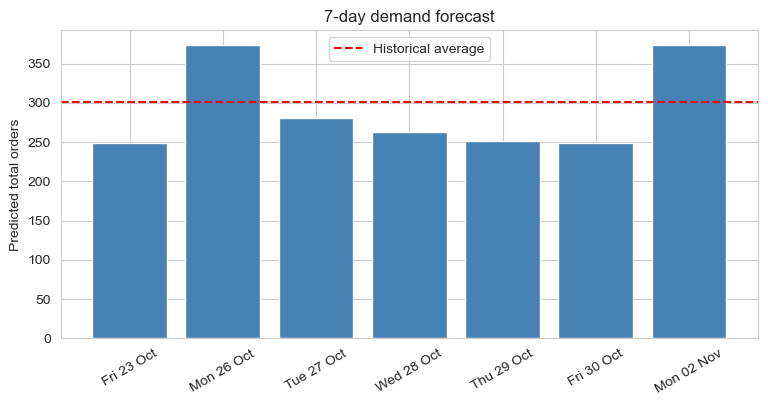

In [62]:
plt.figure(figsize=(9, 4))
labels = [d.strftime("%a %d %b") for d in forecast["date"]]
plt.bar(labels, forecast["predicted_orders"], color="steelblue")
plt.axhline(df[target_col].mean(), color="red", linestyle="--", label="Historical average")
plt.ylabel("Predicted total orders")
plt.title("7-day demand forecast")
plt.xticks(rotation=30)
plt.legend()
plt.show()

**Important to explain in the viva:** this is a *scenario* forecast. The model needs same-day order counts, which are unknown in the future, so we assume a typical day for that weekday. The forecast therefore mainly captures the weekday pattern (Monday high, Friday low). If you know that a day will be unusual (e.g. a big banking campaign), you can override the inputs in the API / UI to get a better estimate.

# 15. FastAPI Backend (files in the `backend/` folder)
Create the files in `backend/` (code given separately): `main.py`, `requirements.txt`, `Dockerfile`, `.env.example`.
Test locally with `uvicorn main:app --reload` and open `http://127.0.0.1:8000/docs`.

# 16. Streamlit UI (file `frontend/app.py`)
Two tabs: **Single day** (calendar date picker) and **7-day forecast** (calendar start date, chart, editable inputs).

# 17. Deployment
Backend: Docker image → Render web service. Frontend: Streamlit with the `API_URL` environment variable pointing to the Render URL. See `README.md`.